# <center>
<div style="
    background: #f0f333ff;
    border-left: 5px solid #ecd242ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h1 style="
        text-align: center;
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 600;
    ">
    Exploration - Phase 1
    </h1>
</div>

##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Questions
    </h2>
</div>

La question centrale est : <br>**Parmi nos 10 000 numéros, lesquels sont valides, lesquels ne le sont pas — et lesquels n'ont pas pu être tranchés ?**

Questions préliminaires :

- Combien de pays distincts ? Combien de formats différents pour un même pays ?
- Quelle proportion de lignes porte des caractères qui n'ont rien à faire dans un numéro de TVA ?
- Combien de valeurs vides, et sous combien de formes différentes le vide se présente-t-il ?
- Le pays déclaré dans le CRM correspond-il toujours au préfixe du numéro ?
- Le CSV et l'Excel contiennent-ils vraiment la même chose une fois chargés ? Lequel prenez-vous comme source de vérité, et pourquoi ?
- Les canaux de saisie et les périodes de saisie se ressemblent-ils, ou certains sortent-ils du lot ?

###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Imports
    </h3>
</div>

In [508]:
import pandas as pd
import matplotlib.pyplot as plt

# Reading Data
df_csv = pd.read_csv('../data/numeros_tva.csv', index_col='id', sep=',', keep_default_na = False)
df_xl  = pd.read_excel('../data/numeros_tva.xlsx', index_col='id', keep_default_na = False)
# On met : keep_default_na = False
# pour que les chaines de caractères (même si elles sont vides) ne soit pas indiquées comme 'NaN'

display(df_csv.dtypes)
display(df_xl.dtypes)

raison_sociale    str
pays_declare      str
numero_tva        str
date_saisie       str
source_saisie     str
dtype: object

raison_sociale    str
pays_declare      str
numero_tva        str
date_saisie       str
source_saisie     str
dtype: object

![parameter keep_default_na](../IMAGES/Pandas_keep_default_na.png)

In [509]:
df_csv.head(8)

,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie
id,,,,,
1,Nord Technologies GmbH,DK,DK73224645,2025-07-27,portail_client
2,Solaris Technologies SARL,PT,PT787327239,2024-03-29,reprise_erp
3,Verso Consulting NV,LU,LU71043234,2024-02-16,crm
4,Lumen Distribution Sp. z o.o.,SE,SE.751298146001,2024-02-27,import_fournisseur
5,Textil Services Oy,NL,NL505862176B88,2025-04-14,crm
6,Kappa Logistics AB,DK,DK61530843,2025-01-14,import_fournisseur
7,Textil Services Oy,NL,NL505862176B88,2024-10-14,saisie_manuelle
8,Vertex Industries SARL,SE,SE.314125231601,2025-03-31,reprise_erp


##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Etude des pays
    </h2>
</div>

**Combien de pays distincts ? Combien de formats différents pour un même pays ?**

In [510]:
# Nombre de pays dans le jeu de données.
display(df_csv['pays_declare'].value_counts())
print(f'Il y a {df_csv['pays_declare'].nunique()} pays différents dans le jeu de données')

pays_declare
FR    974
DK    961
BE    959
LU    956
SE    949
PT    947
NL    947
IT    947
PL    939
FI    902
ZZ    115
QQ    109
GB    104
UK    104
XX     87
Name: count, dtype: int64

Il y a 15 pays différents dans le jeu de données


<Axes: ylabel='pays_declare'>

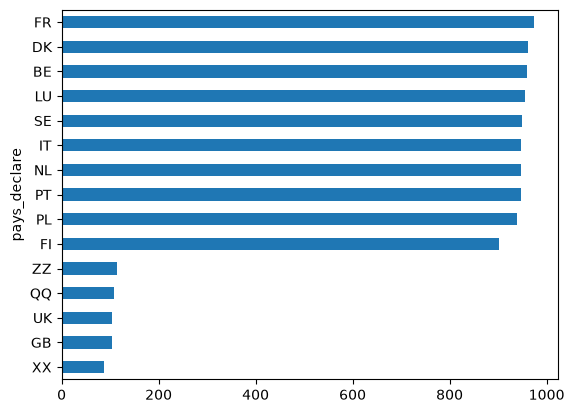

In [511]:
df_csv['pays_declare'].value_counts(ascending=True).plot(kind='barh')

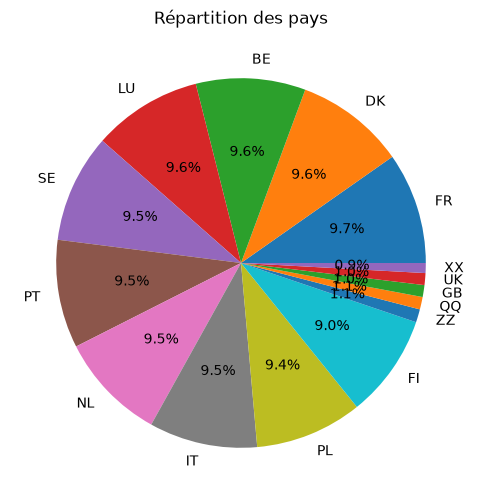

In [512]:
df_csv['pays_declare'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6, 6),
    title='Répartition des pays'
)

plt.ylabel('')
plt.show()

####
<div style="
    background: #eebbefff;
    border-left: 5px solid #d619efff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 400;
    ">
    Etude de quelques formats DR
    </h3>
</div>

In [513]:
df_fr = df_csv[df_csv['pays_declare'] == 'FR']
df_fr_notna = df_fr[df_fr['numero_tva'].notna()]
df_fr.sample(20)

,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie
id,,,,,
9554,Hanse Materials GmbH,FR,FR16958344934,2024-10-08,crm
8999,Kappa Industries A/S,FR,FR96615998916,2024-06-02,crm
2393,Alpine Trading BV,FR,FR921H9776283,2024-07-10,saisie_manuelle
2131,Lusitania Materials NV,FR,FR89569174233,2024-01-06,crm
9489,Solaris Distribution GmbH,FR,FR40102788252,2024-09-10,crm
8271,Kappa Services SARL,FR,FR78522981633,2025-02-06,import_fournisseur
9627,Batavia Consulting SAS,FR,,2025-05-03,reprise_erp
568,Lusitania Distribution SpA,FR,FR.16922728668,2025-03-28,reprise_erp
1347,Alpine Distribution Oy,FR,FR47133877504,2024-06-04,crm


In [514]:
import pandas as pd

def identifier_format(tva):

    if pd.isna(tva):
        return 'Manquant (Nan)'

    tva = str(tva).strip().upper()

    if tva.startswith('FR.'):
        return 'FR point ...'

    elif tva.startswith('FR-'):
        return 'FR tiret ...'

    elif tva.startswith('FRH'):
        return 'FRH ...'

    elif tva == 'NULL':
        return 'NULL'

    elif tva == 'N/A':
        return 'N/A'

    elif tva.startswith('FR') and tva[2:].isdigit():
        return f'FR {len(tva[2:])} chiffres'

    elif tva.startswith('FR') and any(c.isalpha() for c in tva):
        return 'FR avec chiffres, lettres'

    elif tva.isdigit():
        return f'{len(tva)} chiffres (Sans FR)'

    elif tva == '-':
        return 'Tiret seul'

    elif tva == '':
        return 'Vide'

    elif ' ' in tva:
        tva = tva.replace(' ', '')

        if tva.startswith('FR') and tva[2:].isdigit():
            return f'FR {len(tva[2:])} chiffres avec des espaces'

        elif any(c.isalpha() for c in tva):
            return 'FR avec chiffres, lettres et espaces'

    return 'Autre format'


# Détection des différents formats
df_fr_format = df_fr.copy()
df_fr_format['format_TVA'] = df_fr_format['numero_tva'].apply(identifier_format)

print(f"Nb de formats : {df_fr_format['format_TVA'].value_counts().shape[0]}")
print(f"Nb de numéros ayant l'un de ces formats : {df_fr_format['format_TVA'].value_counts().sum()} / {df_fr_format.shape[0]}")
print(f"Nb de numéros manquants : {df_fr_format[df_fr_format['format_TVA'] == 'Manquant (Nan)'].shape[0]}")
print(f'Nb de numéros "Autre format" : {df_fr_format[df_fr_format["format_TVA"] == 'Autre format'].shape[0]}')
print("\nListe des différents format :")
list(df_fr_format['format_TVA'].unique())

Nb de formats : 12
Nb de numéros ayant l'un de ces formats : 974 / 974
Nb de numéros manquants : 0
Nb de numéros "Autre format" : 0

Liste des différents format :


['FR 11 chiffres',
 'FR point ...',
 'Vide',
 '11 chiffres (Sans FR)',
 'FR 12 chiffres',
 'FRH ...',
 'FR tiret ...',
 'FR avec chiffres, lettres',
 'FR 10 chiffres',
 'N/A',
 'Tiret seul',
 'NULL']

In [515]:
df_autre_format = df_fr_format[df_fr_format.format_TVA == 'NULL']
df_autre_format

,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,format_TVA
id,,,,,,
6228,Cobalt Services Sp. z o.o.,FR,null,2024-05-20,crm,NULL
6575,Cobalt Consulting BV,FR,null,2025-06-10,import_fournisseur,NULL
6745,Nord Industries Lda,FR,null,2024-04-10,import_fournisseur,NULL
8226,Vertex Technologies GmbH,FR,null,2025-09-30,portail_client,NULL
8536,Textil Materials Oy,FR,null,2025-01-22,reprise_erp,NULL
8610,Granit Foods SARL,FR,null,2025-08-28,saisie_manuelle,NULL
9525,Kappa Foods SA,FR,null,2025-09-18,crm,NULL


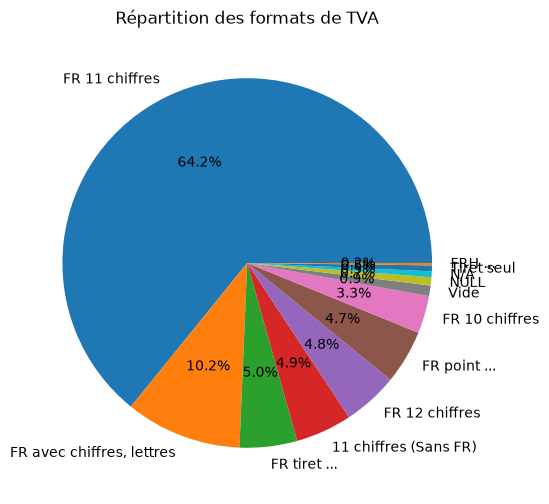

In [516]:
df_fr_format['format_TVA'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6, 6),
    title='Répartition des formats de TVA'
)

plt.ylabel('')
plt.show()

##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Proportion de lignes contenant des caractères qui n'ont rien à faire dans un numéro de TVA ?
    </h2>
</div>

In [517]:
df_spe = df_csv[df_csv['numero_tva'].str.contains(r'[^a-zA-Z0-9]', na=False)]
print(f'Nb de lignes contenant autre chose que des lettres et des chiffres : {df_spe.shape[0]}')
print(f"Proportion de lignes : {100 * df_spe.shape[0] / df_csv.shape[0]:.2f} %")
df_spe.sample(10)
df_spe

Nb de lignes contenant autre chose que des lettres et des chiffres : 1861
Proportion de lignes : 18.61 %


,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie
id,,,,,
4,Lumen Distribution Sp. z o.o.,SE,SE.751298146001,2024-02-27,import_fournisseur
7,Textil Services Oy,NL,NL505862176B88,2024-10-14,saisie_manuelle
8,Vertex Industries SARL,SE,SE.314125231601,2025-03-31,reprise_erp
11,Hanse Distribution SAS,FI,FI.84564443,2024-01-01,saisie_manuelle
13,Alpine Technologies SAS,SE,SE-353056663101,2024-01-04,portail_client
...,...,...,...,...,...
9986,Prima Logistics BV,SE,SE-744347222501,2024-08-30,reprise_erp
9991,Verso Transports SA,SE,SE 6041 26160001,2025-03-12,saisie_manuelle
9992,Fabrica Materials SpA,LU,LU 8783 8948,2024-12-31,crm


##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Nombre de valeurs vides
    </h2>
</div>

In [518]:
display(df_csv.isna().sum())
print(f'Nb de valeurs vides parmi les numéros de TVA : {df_csv.isna().sum()['numero_tva']}')

raison_sociale    0
pays_declare      0
numero_tva        0
date_saisie       0
source_saisie     0
dtype: int64

Nb de valeurs vides parmi les numéros de TVA : 0


###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Recherche des faux NaN
    </h3>
</div>

In [519]:
# df_faux_nan = df_csv[df_csv['numero_tva'].str.strip().isin(['null', 'n/a', 'nan', '', '-']) | (df_csv['numero_tva'].isna())]
df_faux_nan = df_csv[df_csv['numero_tva'].str.strip().str.lower().isin(['null', 'n/a', 'nan', '', '-', 'nu.ll'])]
print(f'Nb de faux nan : {df_faux_nan.shape[0]}')
df_faux_nan.sample(10)

Nb de faux nan : 261


,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie
id,,,,,
2843,Hanse Foods SA,PL,-,2024-06-20,import_fournisseur
9083,Verso Technologies BV,PL,N/A,2024-12-28,portail_client
9447,Baltic Distribution AB,IT,-,2024-03-04,saisie_manuelle
6468,Verso Materials Lda,IT,,2025-06-14,crm
4013,Delta Technologies Lda,IT,,2025-01-28,portail_client
3903,Vertex Trading SA,BE,-,2025-07-27,portail_client
7560,Alpine Materials GmbH,DK,,2024-05-26,import_fournisseur
421,Baltic Transports SpA,IT,null,2025-08-18,portail_client
9812,Prima Trading AB,FI,-,2025-05-22,reprise_erp


On a 6 différents types de faux Nan :
- 'null'
- 'n/a'
- 'nan'
- ''
- '-'
- 'nu.ll (ou NU.LL)

##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Le pays déclaré dans le CRM correspond-il toujours au préfixe du numéro ?
    </h2>
</div>

In [520]:
df_code_country = df_csv.copy()
df_code_country['code_pays_OK'] = df_code_country.apply(
    lambda x : x['pays_declare'].lower() in str(x['numero_tva']).lower(),
    axis = 1
)

print(f"Codes pays correspondants au numéro de TVA : {df_code_country['code_pays_OK'].sum()} / {df_csv.shape[0]}")
print(f"Proportion de codes pays correspondants au numéro de TVA : {100 * df_code_country['code_pays_OK'].sum() / df_csv.shape[0]:.2f} %")

df_code_country[~df_code_country.code_pays_OK].sample(10)

Codes pays correspondants au numéro de TVA : 9207 / 10000
Proportion de codes pays correspondants au numéro de TVA : 92.07 %


,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,code_pays_OK
id,,,,,,
6180,Lusitania Logistics A/S,SE,008195060201,2024-09-03,import_fournisseur,False
294,Solaris Services NV,LU,13176343,2025-09-26,saisie_manuelle,False
5254,Baltic Distribution A/S,DK,null,2024-02-13,portail_client,False
1192,Vertex Consulting Oy,DK,81460655,2024-07-05,reprise_erp,False
264,Ardent Industries Sp. z o.o.,IT,09184526433,2025-08-23,portail_client,False
9886,Metallo Technologies Oy,LU,22061573,2024-12-01,reprise_erp,False
4893,Nord Distribution SA,PL,8078418441,2025-01-26,reprise_erp,False
2040,Cobalt Industries SA,SE,717848736401,2025-03-31,portail_client,False
2934,Atlantic Foods Lda,DK,24833550,2025-01-03,saisie_manuelle,False


##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Comparaison des fichiers CVS et Excel
    </h2>
</div>

**Le CSV et l'Excel contiennent-ils vraiment la même chose une fois chargés ? Lequel prenez-vous comme source de vérité, et pourquoi ?**

In [521]:
# Les noms de colonnes des 2 fichiers sont identiques
print(f'Colonnes du fichier CSV :\t {list(df_csv.columns)}')
print(f'Colonnes du fichier XL  :\t {list(df_xl.columns)}')

Colonnes du fichier CSV :	 ['raison_sociale', 'pays_declare', 'numero_tva', 'date_saisie', 'source_saisie']
Colonnes du fichier XL  :	 ['raison_sociale', 'pays_declare', 'numero_tva', 'date_saisie', 'source_saisie']


In [522]:
# Il y a le même nombre de lignes et de colonnes dans les 2 fichiers
print(f'Taille des données dans le fichier CSV :\t{df_csv.shape}')
print(f'Taille des données dans le fichier XL  :\t{df_csv.shape}')

Taille des données dans le fichier CSV :	(10000, 5)
Taille des données dans le fichier XL  :	(10000, 5)


In [523]:
# Les différences de données entre les 2 fichiers sont dans la colonne : "numero_tva"
print(f"Il y a {df_csv['numero_tva'].shape[0] - (df_csv['numero_tva'] == df_xl['numero_tva']).sum()} valeurs différentes entre les 2 fichiers")
(df_csv == df_xl).sum()

Il y a 0 valeurs différentes entre les 2 fichiers


raison_sociale    10000
pays_declare      10000
numero_tva        10000
date_saisie       10000
source_saisie     10000
dtype: int64

**Conclusion :** 

Les 2 fichiers sont identiques, on utilisera de préférence le fichier CSV car en entreprise les utilisateurs modifient rarement un fichiers CSV alors qu'ils pourraient facilement modifier un fichier Excel.

**Remarque** :

Lors de la lecture des fichiers, on impose de transformer les données en "str" y compris les valeurs vides (NaN), sans ça nos dataframe contiendraient des NaN et il y aurait alors des différences entre les 2 fichiers.

##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Canaux de saisie et périodes de saisie
    </h2>
</div>

**Les canaux de saisie et les périodes de saisie se ressemblent-ils, ou certains sortent-ils du lot ?**

In [524]:
df_csv

,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie
id,,,,,
1,Nord Technologies GmbH,DK,DK73224645,2025-07-27,portail_client
2,Solaris Technologies SARL,PT,PT787327239,2024-03-29,reprise_erp
3,Verso Consulting NV,LU,LU71043234,2024-02-16,crm
4,Lumen Distribution Sp. z o.o.,SE,SE.751298146001,2024-02-27,import_fournisseur
5,Textil Services Oy,NL,NL505862176B88,2025-04-14,crm
...,...,...,...,...,...
9996,Cobalt Trading A/S,PT,PT714332224,2025-01-19,import_fournisseur
9997,Delta Trading Oy,FR,FR60801776699,2025-04-18,crm
9998,Corvus Industries SARL,SE,SE96633532830,2024-09-12,reprise_erp


###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Canaux de saisie
    </h3>
</div>

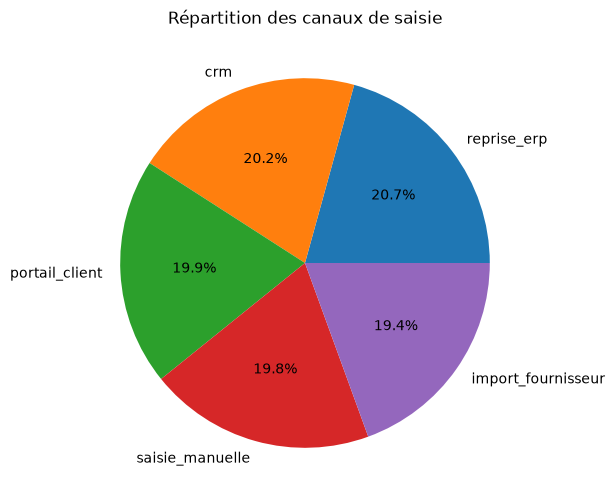

In [525]:
df_csv['source_saisie'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6, 6),
    title='Répartition des canaux de saisie'
)

plt.ylabel('')
plt.show()

**Tous les canaux de saisie sont bien renseignés et appartiennent à 5 catégories** :<br>
- crm
- reprise_erp
- portail_client
- saisie_manuelle
- import_fournisseur

###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Dates de saisie
    </h3>
</div>

**Le type des dates est "String", nous allons le convertir en date**

In [526]:
display(df_csv['date_saisie'].dtypes)
df_csv['date_saisie'] = pd.to_datetime(df_csv['date_saisie'], format="%Y-%m-%d", errors='coerce')
display(df_csv.dtypes)

<StringDtype(storage='python', na_value=nan)>

raison_sociale               str
pays_declare                 str
numero_tva                   str
date_saisie       datetime64[us]
source_saisie                str
dtype: object

**On ajoute des colonnes avec l'année et avec "année-mois"**

In [536]:
df_csv['annee'] = df_csv['date_saisie'].dt.year
df_csv['date_mois'] = df_csv['date_saisie'].dt.to_period('M')
df_csv.sample(5)

,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,annee,date_mois
id,,,,,,,
867,Verso Foods Lda,NL,NL655081331B44,2024-01-10,saisie_manuelle,2024,2024-01
9021,Corvus Trading A/S,IT,IT64701519016,2025-03-09,portail_client,2025,2025-03
1199,Azur Logistics GmbH,FR,FR26721028488,2024-04-23,import_fournisseur,2024,2024-04
7604,Kappa Technologies BV,QQ,QQ51948394,2024-04-04,reprise_erp,2024,2024-04
2270,Ardent Logistics A/S,LU,LU33448119,2025-02-11,saisie_manuelle,2025,2025-02


**On peut afficher la répartition des dates par année**

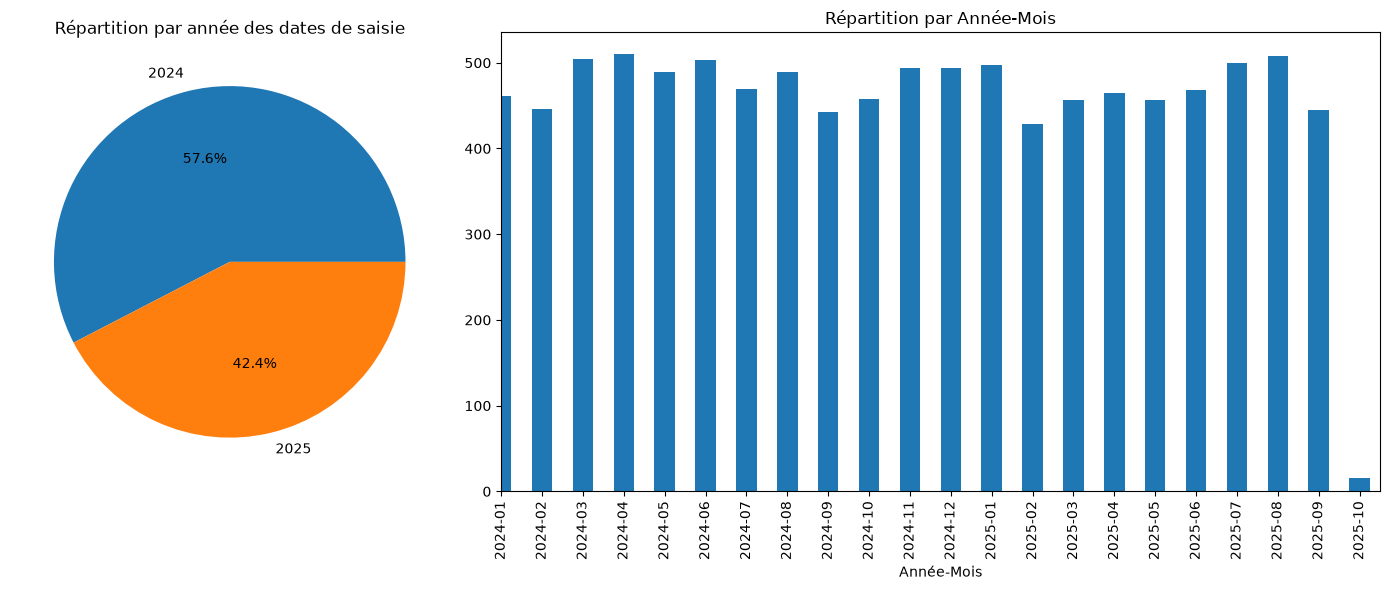

In [581]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                         gridspec_kw={'width_ratios' : [1, 2]})

df_csv['annee'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[0],
    # figsize=(4, 4),
    title='Répartition par année des dates de saisie'
)

df_csv['date_mois'].value_counts().plot(
    kind='bar', 
    xlabel='Année-Mois',
    title='Répartition par Année-Mois',
    ax=axes[1]
    # figsize=(10, 5)
    )

# Ajustement de la disposition
plt.tight_layout()
plt.show()

**On peut aussi faire un graphique de type "Sunburst" pour afficher deux niveaux**

C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_10000\3563190830.py:11: Pandas4Warning: PeriodIndex.values returning an object-dtype ndarray is deprecated. In a future version, this will return the underlying PeriodArray instead. Use 'PeriodIndex.to_numpy()' to get a NumPy array, or 'PeriodIndex.array' to get the ExtensionArray.
  sous_categories = count_annee_mois.index.values


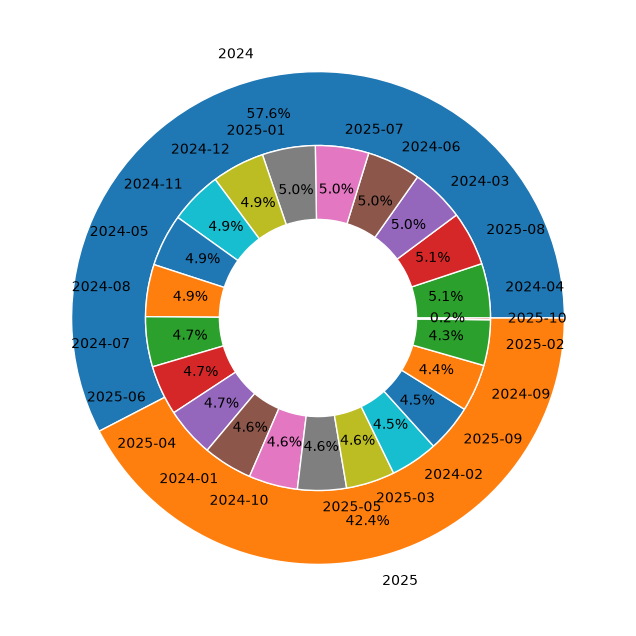

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))

# Niveau 1 : Année
count_annee = df_csv['annee'].value_counts()
categories = count_annee.index.values
valeurs = count_annee.values

# Niveau 2 : Année-Mois
count_annee_mois = df_csv['date_mois'].value_counts()
sous_categories = count_annee_mois.index.values
sous_valeurs = count_annee_mois.values

# Premier niveau
ax.pie(
    valeurs,
    radius=1,
    labels=categories,
    autopct='%1.1f%%',
    pctdistance=0.85,
    wedgeprops=dict(width=0.3, edgecolor='white')
)

# Deuxième niveau
ax.pie(
    sous_valeurs,
    radius=0.7,
    labels=sous_categories,
    autopct='%1.1f%%',
    pctdistance=0.75,
    wedgeprops=dict(width=0.3, edgecolor='white')
)

plt.show()